# Standard Error and the Law of Large Numbers

This notebook accompanies [Standard Error and Law of Large Numbers](../../notes/sampling_and_sampling_distributions/standard_error_and_lln.md). We check by simulation that the standard error of the mean is $\sigma/\sqrt n$, that the standard error of the sum is $\sigma\sqrt n$, and that sample means settle down as $n$ grows.

## Standard error of the mean and of the sum

The population is a box with $\mu=20$ and $\sigma=4$ (a normal population; the formulas hold for any distribution with finite variance).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

mu, sigma = 20.0, 4.0
reps = 20_000
print(f"{'n':>4} {'SE(mean) sim':>13} {'sigma/sqrt n':>13} {'SE(sum) sim':>12} {'sigma*sqrt n':>13}")
for n in (16, 64, 256):
    samples = rng.normal(mu, sigma, size=(reps, n))
    means, sums = samples.mean(axis=1), samples.sum(axis=1)
    print(f"{n:>4} {means.std(ddof=1):>13.4f} {sigma/np.sqrt(n):>13.4f} {sums.std(ddof=1):>12.3f} {sigma*np.sqrt(n):>13.3f}")

   n  SE(mean) sim  sigma/sqrt n  SE(sum) sim  sigma*sqrt n
  16        0.9958        1.0000       15.933        16.000
  64        0.4981        0.5000       31.879        32.000
 256        0.2499        0.2500       63.975        64.000


Quadrupling $n$ halves the standard error of the mean (inverse square-root law) but doubles the standard error of the sum.

## Standard error of a percentage

For a binary variable with success probability $p$, $\sigma=\sqrt{p(1-p)}$ and the standard error of the sample percentage is $100\sigma/\sqrt n$ percent. For $p=0.6$ the note gives $9.8\%$, $4.9\%$ and $2.45\%$ for $n=25,100,400$.

In [2]:
p = 0.6
for n in (25, 100, 400):
    phat = rng.binomial(n, p, size=reps) / n
    theory = 100 * np.sqrt(p * (1 - p) / n)
    print(f"n={n:3d}  simulated SE = {100*phat.std(ddof=1):5.2f}%   formula = {theory:5.2f}%")

n= 25  simulated SE =  9.84%   formula =  9.80%
n=100  simulated SE =  4.91%   formula =  4.90%
n=400  simulated SE =  2.45%   formula =  2.45%


## The Law of Large Numbers

The running mean of i.i.d. draws converges to $\mu$. We follow a single sequence of Exponential(mean 1) draws, and add the $\pm 2\sigma/\sqrt n$ envelope showing how fast it must settle.

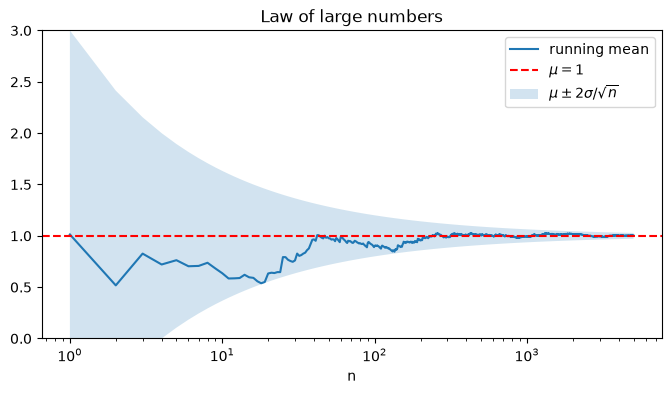

Running mean at n = 10, 100, 1000, 5000: [0.636 0.901 0.991 1.004]


In [3]:
N = 5000
draws = rng.exponential(1.0, N)
running = np.cumsum(draws) / np.arange(1, N + 1)
k = np.arange(1, N + 1)

plt.figure(figsize=(8, 4))
plt.plot(k, running, label="running mean")
plt.axhline(1.0, color="red", linestyle="--", label=r"$\mu = 1$")
plt.fill_between(k, 1 - 2 / np.sqrt(k), 1 + 2 / np.sqrt(k), alpha=0.2, label=r"$\mu \pm 2\sigma/\sqrt{n}$")
plt.ylim(0, 3); plt.xscale("log"); plt.xlabel("n"); plt.legend()
plt.title("Law of large numbers")
plt.show()
print("Running mean at n = 10, 100, 1000, 5000:", np.round(running[[9, 99, 999, 4999]], 3))

## Sums do not settle down

The sum $S_n$ keeps drifting away from zero in absolute terms (its spread grows like $\sqrt n$) even though $S_n/n$ converges. Using centred sums for a fair coin:

In [4]:
coin = rng.integers(0, 2, size=(2000, 10_000))
heads = np.cumsum(coin, axis=1)
n_grid = np.array([100, 1000, 10_000])
for n in n_grid:
    excess = heads[:, n - 1] - n / 2
    print(f"n={n:6d}  sd of (heads - n/2) = {excess.std():7.2f}   sd of proportion = {np.std(heads[:, n-1]/n):.4f}")

n=   100  sd of (heads - n/2) =    5.02   sd of proportion = 0.0502
n=  1000  sd of (heads - n/2) =   15.71   sd of proportion = 0.0157
n= 10000  sd of (heads - n/2) =   49.67   sd of proportion = 0.0050


## A conservative bound: Chebyshev

Chebyshev's inequality gives $P(|\bar X_n-\mu|>\varepsilon)\le\sigma^2/(n\varepsilon^2)$. With $\sigma=2$, $\varepsilon=0.5$, $n=400$ the bound is $0.04$; the normal approximation is vastly smaller. Compare with `scipy.stats.norm`.

In [5]:
sigma, eps, n = 2.0, 0.5, 400
chebyshev = sigma**2 / (n * eps**2)
normal = 2 * stats.norm.sf(eps / (sigma / np.sqrt(n)))
print("Chebyshev bound:", chebyshev)
print("Normal approximation:", normal)

Chebyshev bound: 0.04
Normal approximation: 5.733031437583866e-07


## When the LLN fails: the Cauchy distribution

The Cauchy distribution has no mean, so the running mean never settles.

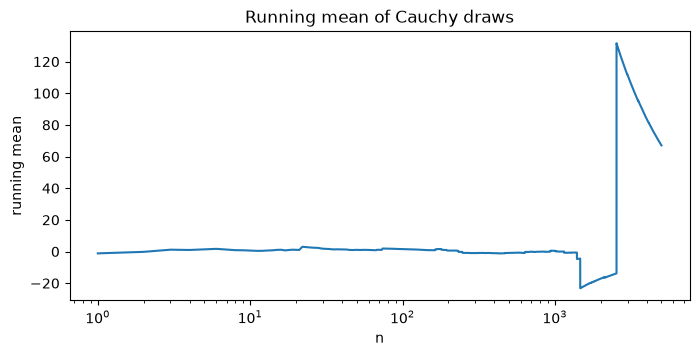

In [6]:
cauchy = rng.standard_cauchy(N)
running_c = np.cumsum(cauchy) / k
plt.figure(figsize=(8, 3.5))
plt.plot(k, running_c)
plt.xscale("log"); plt.xlabel("n"); plt.ylabel("running mean")
plt.title("Running mean of Cauchy draws")
plt.show()